In [1]:
def phase_fold(x, y, period):
    phase = x % period
    order = np.argsort(phase)
    return phase[order], y[order]

def phase_fold_gene(wavetable, period):
    x = np.arange(2, 50, 3)
    y = wavetable
    phase, y_folded = phase_fold(x, y, period)
    return phase, y_folded

### Determine optimal initial length scale for gpflow

Relationship between length scale and correlation between points spaced by fractional periods

In [2]:
import numpy as np
import gpflow
from gpflow.kernels import Periodic, SquaredExponential
from scipy.optimize import brentq

PERIOD = 1.0

def make_kernel(ell):
    base = SquaredExponential(lengthscales=ell, variance=1.0)
    return Periodic(base, period=PERIOD)

def gp_corr(ell, lag):
    """Correlation between f(t) and f(t+lag), read directly from GPflow.
    lag is in the same units as the period (0.5 = half period, 0.25 = quarter)."""
    k = make_kernel(ell)
    X = np.array([[0.0]])
    X2 = np.array([[lag]])
    cov = k(X, X2).numpy()[0, 0]
    var = k.K_diag(X).numpy()[0]
    return cov / var

for ell in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 3.0]:
    print(f"ell={ell:4.2f}  rho@p/8={gp_corr(ell, 0.125):.6f}  rho@p/4={gp_corr(ell, 0.25):.6f}  rho@p/2={gp_corr(ell, 0.5):.6f}")

2026-10-23 02:20:32.386054: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792740036.243808 2027950 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9163 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:0a:00.0, compute capability: 8.9


ell=0.10  rho@p/8=0.000661  rho@p/4=0.000000  rho@p/2=0.000000
ell=0.20  rho@p/8=0.160320  rho@p/4=0.001930  rho@p/2=0.000004
ell=0.40  rho@p/8=0.632772  rho@p/4=0.209611  rho@p/2=0.043937
ell=0.60  rho@p/8=0.815953  rho@p/4=0.499352  rho@p/2=0.249352
ell=0.80  rho@p/8=0.891891  rho@p/4=0.676634  rho@p/2=0.457833
ell=1.00  rho@p/8=0.929393  rho@p/4=0.778801  rho@p/2=0.606531
ell=1.50  rho@p/8=0.967980  rho@p/4=0.894839  rho@p/2=0.800737
ell=2.00  rho@p/8=0.981861  rho@p/4=0.939413  rho@p/2=0.882497
ell=3.00  rho@p/8=0.991897  rho@p/4=0.972604  rho@p/2=0.945959


Try fitting a few high confidence genes with multiple initial length scales and see if they converge

In [3]:
import gpflow
import tensorflow as tf
import tensorflow_probability as tfp
from astropy.timeseries import LombScargle
import numpy as np

tfd = tfp.distributions

def fit_gp_gpflow_no_ls_prior(x, y, period, best_power, length_scale_initial):
    x = x.reshape(-1, 1).astype(np.float64)
    y = y.reshape(-1, 1).astype(np.float64)
    y_mean = np.mean(y).astype(float)
    mean_fn = gpflow.mean_functions.Constant(c=y_mean)
    y_std = np.std(y).astype(float) + 1e-9
    kernel = gpflow.kernels.Periodic(
        gpflow.kernels.SquaredExponential(
            variance = y_std**2,
            lengthscales=length_scale_initial
        ),
        period=period,
    )
    gpflow.utilities.set_trainable(kernel.period, False) #Trust Lomb_Scargle

    # kernel.base_kernel.lengthscales.prior = tfd.LogNormal(
    #     loc = tf.cast(tf.math.log(length_scale_initial), tf.float64),
    #     scale=tf.cast(0.5, tf.float64)
    # )
    kernel.base_kernel.variance.prior = tfd.LogNormal(
        loc=tf.cast(tf.math.log(y_std**2), tf.float64),
        scale=tf.cast(1.0, tf.float64)
    )

    model = gpflow.models.GPR(
        data=(x,y),
        kernel=kernel,
        mean_function=mean_fn,
    )

    #Calculate noise after fitting LS
    var_y = np.var(y)
    # best_power = LombScargle(x.ravel(), y.ravel()).power(1/period)
    resid_var = (1.0 - best_power)*var_y

    model.likelihood.variance.assign(resid_var)
    model.likelihood.variance.prior = tfd.LogNormal(
        loc=tf.cast(tf.math.log(resid_var), tf.float64),
        scale=tf.cast(1.0, tf.float64)
    )

    opt = gpflow.optimizers.Scipy()
    opt.minimize(
        model.training_loss,
        model.trainable_variables,
        options={"maxiter": 500}
    )

    return model

In [4]:
import pandas as pd
dat = pd.read_csv("../Processed_Data/VST.csv")
freq_dat = pd.read_csv("../Processed_Data/ls.csv")

set_low = freq_dat[(freq_dat['qval'] <= 0.05) & (freq_dat['best_period'] <= 12)]
set_mid = freq_dat[(freq_dat['qval'] <= 0.05) & (freq_dat['best_period'] > 12) & (freq_dat['best_period'] <= 24)]
set_mid= set_mid.sample(n = 10, replace = False, random_state=123)
set_high = freq_dat[(freq_dat['qval'] <= 0.05) & (freq_dat['best_period'] > 24) & (freq_dat['best_period'] <= 48)]
set_high= set_high.sample(n = 10, replace = False, random_state=123)

In [5]:
def model_ls_fitting(set):
    ls_out = []
    for GeneID in set['GeneID']:
        for init_ls in [0.1, 0.5, 1.0, 5, 10]:
            g_dat = dat[dat.GeneID == GeneID].drop(columns=['GeneID']).to_numpy().squeeze()
            g_period= freq_dat[freq_dat['GeneID'] == GeneID].best_period.item()
            best_power = freq_dat[freq_dat['GeneID'] == GeneID].best_power.item()
            model = fit_gp_gpflow_no_ls_prior(np.arange(2, 50, 3), g_dat, g_period, best_power, length_scale_initial=init_ls)
            row = {
                'GeneID':GeneID,
                'ls_init': init_ls,
                'ls_fit' : model.kernel.base_kernel.lengthscales.numpy(),
                'loss': model.training_loss().numpy(),}
            ls_out.append(row)

    df = pd.DataFrame(ls_out)
    df = df.loc[df.groupby("GeneID")["loss"].idxmin()]
    log_ls_fit = np.log(df.ls_fit.to_numpy(dtype=float))
    sd_log_ls = np.std(log_ls_fit)
    median_ls = np.median(df.ls_fit.to_numpy(dtype=float))
    return df, median_ls, sd_log_ls


In [6]:
set_low_fit, set_low_median_ls, set_low_sd_log_ls = model_ls_fitting(set_low)
print(set_low_fit.head())
print(f"log_std: {set_low_sd_log_ls}; median: {set_low_median_ls}")

I0000 00:00:1792740040.283019 2028020 cuda_solvers.cc:175] Creating GpuSolver handles for stream 0x63e8dc84b550


      GeneID  ls_init               ls_fit       loss
3  AT1G32150      5.0  0.42949397918394083 -24.010971
8  AT5G46400      5.0   0.1374838061423018 -21.954209
log_std: 0.5695507932338815; median: 0.28348889266312133


In [7]:
set_mid_fit, set_mid_median_ls, set_mid_sd_log_ls = model_ls_fitting(set_mid)
print(set_mid_fit.head())
print(f"log_std: {set_mid_sd_log_ls}; median: {set_mid_median_ls}")

       GeneID  ls_init               ls_fit       loss
42  AT1G07050      1.0   0.5759872588642152  15.254964
2   AT1G07930      1.0    0.583623325149609 -20.418228
35  AT1G09795      0.1  0.40996052724277454 -12.888341
13  AT2G25080      5.0    0.604137074815007  -0.001704
16  AT3G09600      0.5  0.44416875098442005  15.806985
log_std: 0.33529833927859165; median: 0.42706463911359727


In [8]:
set_high_fit, set_high_median_ls, set_high_sd_log_ls = model_ls_fitting(set_high)
print(set_high_fit.head())
print(f"log_std: {set_high_sd_log_ls}; median: {set_high_median_ls}")

       GeneID  ls_init              ls_fit       loss
17  AT1G49720      1.0  0.4614903762844469   5.355148
12  AT1G54130      1.0  0.3974806308197964  -8.109143
6   AT2G16640      0.5  0.5846388754024798 -12.412278
24  AT2G33540     10.0  0.5516954501357197 -20.119944
26  AT3G05820      0.5  0.5047812533098908 -13.886926
log_std: 0.12324057167239134; median: 0.5168722559234904


The median of well fitted periodic genes show about 0.4~0.5 of fitted length scale that seem to vary slightly based on detected period. I'm choosing the lower end of 0.4, which also gives less correlation to points half a period apart based on the table above. I'll also choose a log std of 0.35 to be slightly more conservative based on the observed results.

## Gp flow

In [9]:
# keep everything in one place
from gp_functions import fit_gp_gpflow, fit_gp_with_qc, sample_waveforms_gpflow

Hand check a few problematic genes

----------AT1G01050-----------
period = 24.489795918367346 ; variance = 0.039136422202583794
╒═════════════════════════════════════╤═══════════╤══════════════════╤═══════════╤═════════════╤═════════╤═════════╤════════════╕
│ name                                │ class     │ transform        │ prior     │ trainable   │ shape   │ dtype   │      value │
╞═════════════════════════════════════╪═══════════╪══════════════════╪═══════════╪═════════════╪═════════╪═════════╪════════════╡
│ GPR.mean_function.c                 │ Parameter │ Identity         │           │ True        │ ()      │ float64 │ 10.3188    │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼────────────┤
│ GPR.kernel.base_kernel.variance     │ Parameter │ Softplus         │ LogNormal │ True        │ ()      │ float64 │  0.0273021 │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼───────────

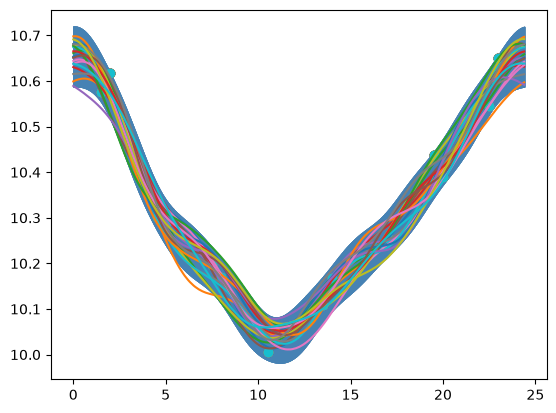

----------AT4G17810-----------
period = 12.148481439820022 ; variance = 0.05956373418646096
╒═════════════════════════════════════╤═══════════╤══════════════════╤═══════════╤═════════════╤═════════╤═════════╤════════════╕
│ name                                │ class     │ transform        │ prior     │ trainable   │ shape   │ dtype   │      value │
╞═════════════════════════════════════╪═══════════╪══════════════════╪═══════════╪═════════════╪═════════╪═════════╪════════════╡
│ GPR.mean_function.c                 │ Parameter │ Identity         │           │ True        │ ()      │ float64 │  8.16779   │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼────────────┤
│ GPR.kernel.base_kernel.variance     │ Parameter │ Softplus         │ LogNormal │ True        │ ()      │ float64 │  0.0356486 │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼────────────

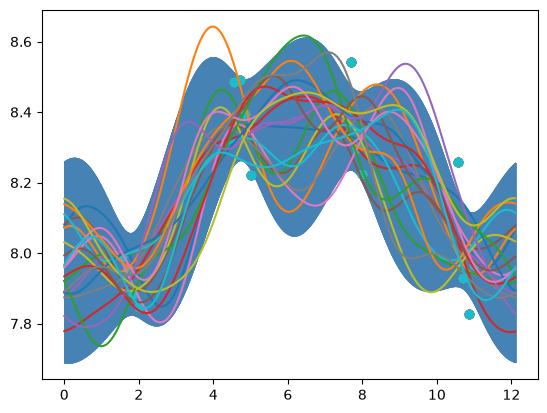

----------AT5G17000-----------
period = 24.05345211581292 ; variance = 0.06809522294888459
╒═════════════════════════════════════╤═══════════╤══════════════════╤═══════════╤═════════════╤═════════╤═════════╤═════════════╕
│ name                                │ class     │ transform        │ prior     │ trainable   │ shape   │ dtype   │       value │
╞═════════════════════════════════════╪═══════════╪══════════════════╪═══════════╪═════════════╪═════════╪═════════╪═════════════╡
│ GPR.mean_function.c                 │ Parameter │ Identity         │           │ True        │ ()      │ float64 │  8.84623    │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼─────────────┤
│ GPR.kernel.base_kernel.variance     │ Parameter │ Softplus         │ LogNormal │ True        │ ()      │ float64 │  0.0532283  │
├─────────────────────────────────────┼───────────┼──────────────────┼───────────┼─────────────┼─────────┼─────────┼───────

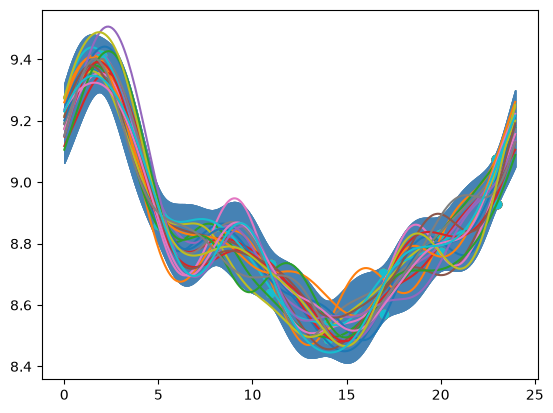

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
VST_dat = pd.read_csv("../Processed_Data/VST.csv")
freq_dat = pd.read_csv("../Processed_Data/ls.csv")
GeneIDs = ["AT1G01050", "AT4G17810", "AT5G17000"]# "AT1G54870", "AT3G21670", "AT1G02670", "AT4G17810", "AT4G03410"]
rows = []
qc_all = []
for GeneID in GeneIDs:
    row = {}
    g_dat = VST_dat[VST_dat.GeneID == GeneID].drop(columns=['GeneID']).to_numpy().squeeze()
    g_period= freq_dat[freq_dat['GeneID'] == GeneID].best_period.item()
    best_power = freq_dat[freq_dat['GeneID'] == GeneID].best_power.item()
    gp = fit_gp_gpflow(np.arange(2, 50, 3), g_dat, g_period, best_power)
    print(f"----------{GeneID}-----------")
    print(f"period = {g_period} ; variance = {np.var(g_dat)}")
    print(gpflow.utilities.print_summary(gp))
    model, qc = fit_gp_with_qc(np.arange(2, 50, 3), g_dat, g_period, best_power)
    samples, grid = sample_waveforms_gpflow(model, g_period, n_samples=20, n_grid=256, seed=123)
    g_phase, g_y_folded = phase_fold_gene(g_dat, g_period)
    mu, var = model.predict_f(np.array(grid).reshape(-1,1))
    mu = mu.numpy().ravel()
    std = np.sqrt(var.numpy().ravel())
    for sample in samples:
        plt.fill_between(grid, mu - 2* std, mu + 2* std, color = "steelblue", alpha = 0.25)
        plt.plot(grid, sample)
        plt.scatter(g_phase, g_y_folded)

    plt.show()
    qc_all.append(qc)

In [11]:
# Drop per-grid arrays for a readable summary table
pd.DataFrame([{k: v for k, v in qc.items() if k not in ("mu", "std")} for qc in qc_all])

,ls_fit,amplitude,noise,noise_frac_model,noise_frac_data,ls_sensitivity_ratio,shape_sensitivity,relative_std
0,0.403665,0.017407,0.001295,0.069240,0.033087,0.313814,0.069329,0.134646
1,0.308496,0.026297,0.014324,0.352626,0.240480,0.787234,0.899464,0.624208
2,0.311337,0.039114,0.004288,0.098793,0.062968,0.274060,0.085681,0.229429


### Determine which QC metric to output

In [12]:
from tqdm import tqdm

VST_dat = pd.read_csv("../Processed_Data/VST.csv")
freq_dat = pd.read_csv("../Processed_Data/ls.csv")
Norm_dat = pd.read_csv("../Processed_Data/Normalized_counts.csv")[["GeneID", "log_TPM"]]
freq_dat = freq_dat.sample(100, replace=False, random_state=123)
qc_all = []

for GeneID in tqdm(freq_dat.GeneID):
    g_dat = VST_dat[VST_dat.GeneID == GeneID].drop(columns=['GeneID']).to_numpy().squeeze()
    g_period = freq_dat[freq_dat['GeneID'] == GeneID].best_period.item()
    best_power = freq_dat[freq_dat['GeneID'] == GeneID].best_power.item()
    g_TPM = Norm_dat[Norm_dat['GeneID'] == GeneID].log_TPM.item()
    model, qc = fit_gp_with_qc(np.arange(2, 50, 3), g_dat, g_period, best_power)
    # Drop per-grid arrays for the summary table
    qc_row = {k: v for k, v in qc.items() if k not in ("mu", "std")}
    qc_row["log_TPM"] = g_TPM
    qc_all.append(qc_row)

100%|██████████| 100/100 [01:43<00:00,  1.04s/it]


In [13]:
df = pd.DataFrame(qc_all)
df[['noise_frac_model', 'noise_frac_data', 'ls_sensitivity_ratio', 'shape_sensitivity', 'relative_std', 'log_TPM']].corr(method="spearman")

,noise_frac_model,noise_frac_data,ls_sensitivity_ratio,shape_sensitivity,relative_std,log_TPM
noise_frac_model,1.000000,0.987183,0.734221,0.544254,0.947543,-0.150279
noise_frac_data,0.987183,1.000000,0.752499,0.597336,0.980726,-0.179310
ls_sensitivity_ratio,0.734221,0.752499,1.000000,0.810765,0.761356,-0.250513
shape_sensitivity,0.544254,0.597336,0.810765,1.000000,0.653681,-0.339778
relative_std,0.947543,0.980726,0.761356,0.653681,1.000000,-0.219322
log_TPM,-0.150279,-0.179310,-0.250513,-0.339778,-0.219322,1.000000


These metrics all correlate well enough (apart from log_TPM, which is good) with each other that I'll only keep relative_std as a single metric to capture a sense of the fitting quality.

### Parallelize and Run All

In [14]:
import numpy as np
import pandas as pd
import multiprocessing as mp
import time
from tqdm import tqdm
from gp_worker import fit_single_gene
from gp_functions import DEFAULT_LENGTH_SCALE
import json

def np_to_list_or_bypass(row):
    out = {}
    for k, v in row.items():
        if isinstance(v, np.ndarray):
            out[k] = v.tolist()
        elif isinstance(v, (np.floating, np.integer)):
            out[k] = v.item()
        else:
            out[k] = v
    return out


def fit_all_genes(output_path, vst_dat, freq_dat, tpm_dat, length_scale_initial=DEFAULT_LENGTH_SCALE,
                  n_workers=None, chunksize=10):
    """Fit GP on VST expression for every gene in freq_dat (ls.csv)."""
    if n_workers is None:
        n_workers = max(1, mp.cpu_count() - 1)

    vst_indexed = vst_dat.set_index("GeneID")
    tpm_indexed = tpm_dat.set_index("GeneID")["log_TPM"]
    freq_indexed = freq_dat.set_index("GeneID")

    args_list = []
    for GeneID in freq_dat["GeneID"]:
        dat = vst_indexed.loc[GeneID].to_numpy(dtype=float)
        row = freq_indexed.loc[GeneID]
        args_list.append((
            GeneID,
            dat,
            float(row.best_period),
            float(row.phase_hours),
            float(row.best_power),
            float(row.qval),
            float(row.log_period_sd),
            float(row.period_sd),
            float(row.period_low95),
            float(row.period_high95),
            float(tpm_indexed.loc[GeneID]),
            length_scale_initial,
        ))

    print(f"fitting {len(args_list)} genes on {n_workers} workers!")

    t0 = time.time()
    ctx = mp.get_context("spawn")
    results = []
    with ctx.Pool(processes=n_workers) as pool:
        with open(output_path, "w") as f:
            for result in tqdm(
                pool.imap_unordered(fit_single_gene, args_list, chunksize=chunksize),
                total=len(args_list),
                desc="Processing...",
            ):
                results.append(result)
                f.write(json.dumps(np_to_list_or_bypass(result)) + "\n")

    elapsed = time.time() - t0
    n_ok = sum(bool(r.get("success")) for r in results)
    print(f"job completed in {elapsed:.1f} seconds: {n_ok}/{len(results)} successes")
    return results

In [ ]:
VST_dat = pd.read_csv("../Processed_Data/VST.csv")
freq_dat = pd.read_csv("../Processed_Data/ls.csv")
Norm_dat = pd.read_csv("../Processed_Data/Normalized_counts.csv")[["GeneID", "log_TPM"]]
results = fit_all_genes(
    "../Processed_Data/Sampled_dat.json",
    VST_dat,
    freq_dat,
    Norm_dat,
    length_scale_initial=DEFAULT_LENGTH_SCALE,
    n_workers=None,
    chunksize=10,
)
# ~3.3k genes: Took 10min

fitting 3286 genes on 23 workers!


Processing...:   0%|          | 0/3286 [00:00<?, ?it/s]2026-10-23 02:27:47.776905: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-23 02:27:47.781740: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-23 02:27:47.801320: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-2

job completed in 586.6 seconds: 3286/3286 successes


In [16]:
import json
from pathlib import Path

N_GRID = 256
N_SAMPLES = 10
WAVE_KEYS = [f"sample_{i+1}" for i in range(N_SAMPLES)] + ["mu", "std"]
N_WAVES = len(WAVE_KEYS)
BYTES_PER_GENE = N_GRID * N_WAVES * 4

META_KEYS = [
    "GeneID", "period", "phase", "qval", "best_power",
    "log_period_sd", "period_sd", "period_low95", "period_high95",
    "log_TPM", "relative_std", "shape_sensitivity",
]

results = []
with open("../Processed_Data/Sampled_dat.json", "r") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        results.append(json.loads(line))

results = [r for r in results if r.get("success")]
print(f"exporting {len(results)} successful fits")

meta = []
with open("../Processed_Data/waveforms.bin", "wb") as binfile:
    for row in results:
        gene_data = np.concatenate([
            np.asarray(row[key], dtype=np.float32) for key in WAVE_KEYS
        ])
        assert gene_data.size == N_GRID * N_WAVES, (row["GeneID"], gene_data.size)
        binfile.write(gene_data.tobytes())
        meta.append({k: row[k] for k in META_KEYS})

meta_out = {
    "N_GRID": N_GRID,
    "N_SAMPLES": N_SAMPLES,
    "N_WAVES": N_WAVES,
    "BYTE_OFFSET": BYTES_PER_GENE,
    "WAVE_KEYS": WAVE_KEYS,
    "meta": meta,
}

meta_path = Path("../Processed_Data/bin_meta.json")
meta_dat = json.loads(meta_path.read_text(encoding="utf-8"))
meta_dat["waveforms.bin"] = meta_out

with open(meta_path, "w") as f:
    json.dump(meta_dat, f)
print("wrote waveforms.bin and updated bin_meta.json")


exporting 3286 successful fits
wrote waveforms.bin and updated bin_meta.json
